# Image classification with pretrained model (ResNet)

The data use in this analysis contains only bags and shoes and can be found on this [URL](https://www.dropbox.com/s/w07liww46kgxo1m/handbags-shoes.zip)  
Firstly, i am going to build a base model with a basic CNN model  
then, I will build a second model using the weight from the ResNet50 model.

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random as python_random
import os, shutil, pathlib

In [2]:
keras.utils.set_random_seed(40)

In [3]:
!unzip -qq handbags-shoes.zip

In [4]:
## Filter out corrupted images

num_skipped = 0
for folder_name in ("handbags", "shoes"):
    folder_path = os.path.join("handbags-shoes", folder_name)
    for fname in os.listdir(folder_path):
        fpath = os.path.join(folder_path, fname)
        try:
            fobj = open(fpath, "rb")
            is_jfif = b"JFIF" in fobj.peek(10)
        finally:
            fobj.close()

        if not is_jfif:
            num_skipped += 1
            # Delete corrupted image
            os.remove(fpath)

print(f"Deleted {num_skipped} images.")


Deleted 25 images.


In [5]:
#Split the data
base_dir = pathlib.Path("handbags-shoes")

for category in ('handbags', 'shoes'):
  fnames = os.listdir(base_dir/category)
  dir = base_dir /'train' / category
  os.makedirs(dir)
  for fname in fnames[:50]:
      shutil.copyfile(src=base_dir/category/fname,
                      dst=dir/fname)
  dir = base_dir /'validation' / category
  os.makedirs(dir)
  for fname in fnames[50:75]:
      shutil.copyfile(src=base_dir/category/fname,
                      dst=dir/fname)
  dir = base_dir /'test' / category
  os.makedirs(dir)
  for fname in fnames[75:]:
      shutil.copyfile(src=base_dir/category/fname,
                      dst=dir/fname)

## Data preprocessing
**image_dataset_from_directory** function in Keras automatically create categories based on folder structure. 

Each images are 224 by 224 pixels


In [6]:
from tensorflow.keras.preprocessing import image_dataset_from_directory

train_dataset = image_dataset_from_directory(
    base_dir / 'train',
    image_size=(224, 224),
    batch_size=32)

validation_dataset = image_dataset_from_directory(
    base_dir / 'validation',
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)

test_dataset = image_dataset_from_directory(
    base_dir / 'test',
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)

class_names = train_dataset.class_names
print(class_names)

Found 98 files belonging to 2 classes.
Found 47 files belonging to 2 classes.
Found 15 files belonging to 2 classes.
['handbags', 'shoes']


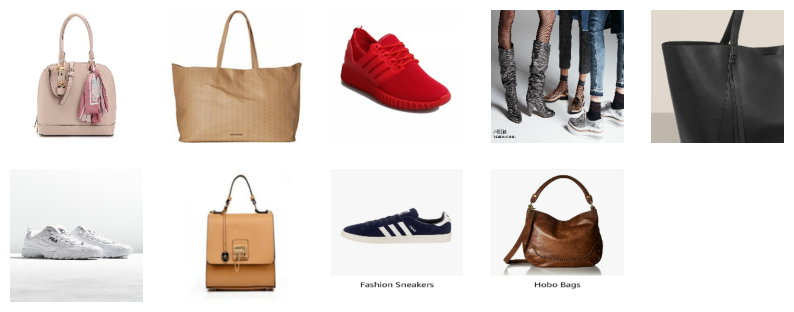

In [7]:
## visualising the data 

plt.figure(figsize=(10, 10))
for images, _ in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(5, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.axis("off")

### The CNN base model
- data Augmentation since training set is just 98

In [8]:
data_augmentation_layers = [
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1)
]


def data_augmentation(images):
    for layer in data_augmentation_layers:
        images = layer(images)
    return images

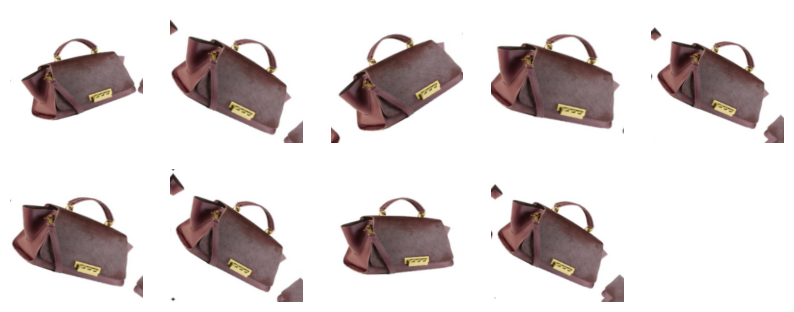

In [9]:
## Visualise the augmented data

plt.figure(figsize=(10, 10))
for images, _ in train_dataset.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images)
        ax = plt.subplot(5, 5, i + 1)
        plt.imshow(np.array(augmented_images[0]).astype("uint8"))
        plt.axis("off")

In [10]:
def build_cnn_model():
    input = keras.Input(shape=(224,224,3))

    h = keras.layers.Rescaling(1./255)(input)
    
    # convolutional layer!
    h = keras.layers.Conv2D(32, kernel_size=(2, 2), activation="relu", name="Conv_1")(h) 
    # pooling layer
    h = keras.layers.MaxPool2D()(h) 
    
    
    # convolutional layer!
    h = keras.layers.Conv2D(32, kernel_size=(2, 2), activation="relu", name="Conv_2")(h) 
    # pooling layer
    h = keras.layers.MaxPool2D()(h) 
    
    
    h = keras.layers.Flatten()(h)   
    output = keras.layers.Dense(1, activation="sigmoid")(h)
    
    model = keras.Model(input, output)

    model.summary()

    model.compile(loss='binary_crossentropy',
             optimizer='adam',
             metrics=['accuracy'])

    return model

In [11]:
base_model = build_cnn_model()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_1 (Conv2D)                 │ (None, 223, 223, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv2D)                 │ (None, 110, 110, 32)   │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 55, 55, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 96800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        96,801 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,345 (395.88 KB)

 Trainable params: 101,345 (395.88 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
difficult_classes = [0]
data_augmentation = keras.Sequential([
    keras.layers.RandomZoom(0.1)
], name="handbag_augmentation")

def augment_handbags(images, labels):
    augmented_images = data_augmentation(
        images, training=True
    )

    # Class 0 = handbags
    mask = tf.equal(labels, 0)
    mask = mask[:, tf.newaxis, tf.newaxis, tf.newaxis]

    # Augment handbags;
    images = tf.where(mask, augmented_images, images)

    return images, labels


augmented_train_dataset = train_dataset.map(
    augment_handbags,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

In [13]:
base_history = base_model.fit(augmented_train_dataset, epochs=20, validation_data=validation_dataset)

/Users/azeezatmustapha/venvs/scrna-ml/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 280ms/step - accuracy: 0.4796 - loss: 1.2566 - val_accuracy: 0.7660 - val_loss: 0.5532
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 169ms/step - accuracy: 0.5918 - loss: 0.6933 - val_accuracy: 0.6170 - val_loss: 0.6570
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 269ms/step - accuracy: 0.7449 - loss: 0.5169 - val_accuracy: 0.8085 - val_loss: 0.4982
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 153ms/step - accuracy: 0.8776 - loss: 0.4104 - val_accuracy: 0.7021 - val_loss: 0.5268
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 147ms/step - accuracy: 0.8265 - loss: 0.3626 - val_accuracy: 0.8936 - val_loss: 0.4101
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 172ms/step - accuracy: 0.8980 - loss: 0.2904 - val_accuracy: 0.8723 - val_loss: 0.4015
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 144ms/step - accuracy: 0.8878 - loss: 0.2986 - val_accuracy: 0.8511 - val_loss: 0.4115
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step - accuracy: 0.9388 - loss: 0.2056 - val_accuracy: 0.8298 - val_loss:

In [14]:
## Helper functions
def plot_loss_curves(history):
  plt.clf()
  history_dict = history.history
  loss_values = history_dict["loss"]
  val_loss_values = history_dict["val_loss"]
  epochs = range(1, len(loss_values) + 1)
  plt.plot(epochs, loss_values, "bo", label="Training loss")
  plt.plot(epochs, val_loss_values, "b", label="Validation loss")
  plt.title("Training and validation loss")
  plt.xlabel("Epochs")
  plt.ylabel("Loss")
  plt.legend()
  plt.show()


def plot_acc_curves(history):
  plt.clf()
  history_dict = history.history
  acc = history_dict["accuracy"]
  val_acc = history_dict["val_accuracy"]
  epochs = range(1, len(acc) + 1)
  plt.plot(epochs, acc, "bo", label="Training acc")
  plt.plot(epochs, val_acc, "b", label="Validation acc")
  plt.title("Training and validation accuracy")
  plt.xlabel("Epochs")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.show()

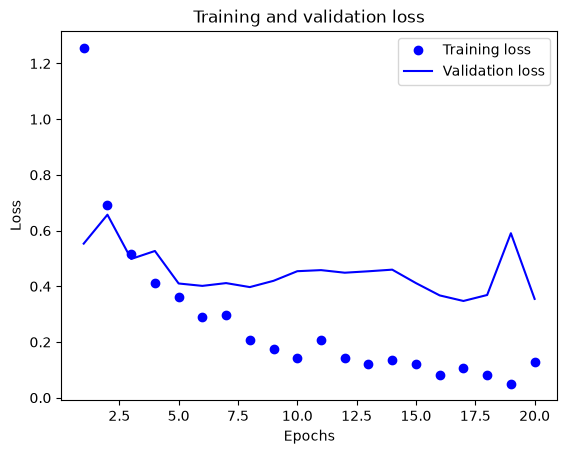

In [15]:
plot_loss_curves(base_history)

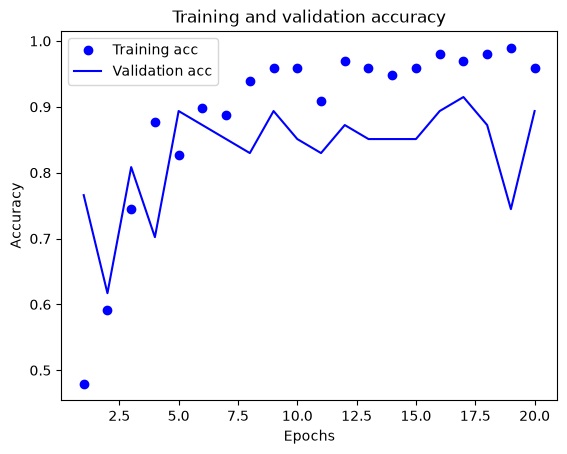

In [16]:
plot_acc_curves(base_history)

In [17]:
base_model.evaluate(test_dataset)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 1.0000 - loss: 0.1029


[0.10290651023387909, 1.0]

**93%** Accuracy on test data set

In [18]:
image_size = (224, 224)
def pred(img_path):
    img = keras.utils.load_img(img_path, target_size=image_size)
    plt.imshow(img)
    plt.axis("off")
    plt.show()

    img_array = keras.utils.img_to_array(img)
    img_array = keras.ops.expand_dims(img_array, 0)

    predictions = base_model.predict(img_array, verbose=0)
    score = float(predictions[0][0])

    predicted_class = "SHOE" if score > 0.0 else "HANDBAG"

    print("************************************")
    print(f"It is a {predicted_class}!")
    print("************************************")


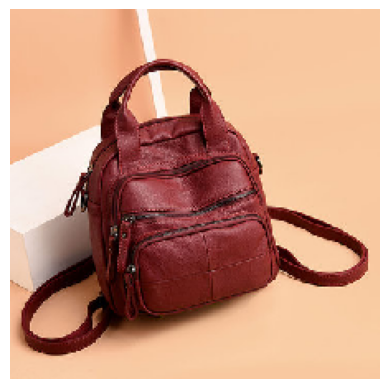

************************************
It is a SHOE!
************************************


In [19]:
bag = "handbags-shoes/test/handbags/20. 48775b47-9720-4601-bf69-3be6fee45093.jpg"
shoe = "shoe.jpg"

pred(bag)

### Despite the adding augumentation because the model struggles to identify bags, the model still struggles

The training data is only 98. We transfer knowledge of a model that is already trained on a larger data set and use it to train our 98 dataset.

# Knowledge transfer with ResNet

In [20]:
resnet50_base = keras.applications.ResNet50(
  weights='imagenet',
  include_top=False,
  input_shape=(224, 224, 3))

In [21]:
def get_features_and_labels(dataset):
  all_features = []
  all_labels = []
  for images, labels in dataset:
    preprocessed_images = keras.applications.resnet50.preprocess_input(images)
    features = resnet50_base.predict(preprocessed_images)
    all_features.append(features)
    all_labels.append(labels)
  return np.concatenate(all_features), np.concatenate(all_labels)

In [22]:
train_features, train_labels =  get_features_and_labels(train_dataset)
val_features, val_labels =  get_features_and_labels(validation_dataset)
test_features, test_labels =  get_features_and_labels(test_dataset)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 874ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 581ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 818ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step


In [23]:
train_features.shape

(98, 7, 7, 2048)

In [24]:
def make_model():
    input = keras.Input(shape=(7, 7, 2048))
    h = keras.layers.Flatten()(input)
    h = keras.layers.Dense(256, activation="relu")(h)
    h = keras.layers.Dropout(0.2)(h)
    output = keras.layers.Dense(1, activation="sigmoid")(h)
    
    model = keras.Model(input, output)
    print(model.summary())

    model.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])
    return model

In [25]:
model = make_model()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 7, 7, 2048)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,690,625 (98.00 MB)

 Trainable params: 25,690,625 (98.00 MB)

 Non-trainable params: 0 (0.00 B)

None


In [26]:
history = model.fit(
  train_features, train_labels,
  epochs=10,
  validation_data=(val_features, val_labels))

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.7245 - loss: 19.9449WARNING:tensorflow:5 out of the last 122 calls to <function TensorFlowTrainer._make_function.<locals>.one_step_on_data at 0x178beef00> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 170ms/step - accuracy: 0.7245 - loss: 19.9449 - val_accuracy: 0.8085 - val_loss: 11.4920
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.8469 - loss: 12.1340 - val_accurac

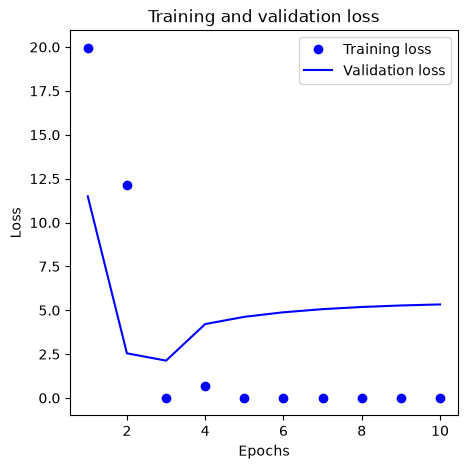

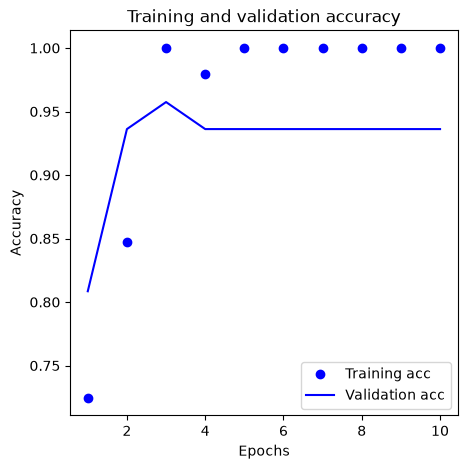

In [27]:
plt.figure(figsize=(5, 5))
plot_loss_curves(history)
plt.figure(figsize=(5, 5))
plot_acc_curves(history)

## Training and validation loss got 0 while Accuracy got to 1

In [28]:
model.evaluate(test_features, test_labels)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9333 - loss: 2.7363


[2.7362754344940186, 0.9333333373069763]

### Predicting with images from the internet

In [29]:
def predict_image(im):
    img = keras.preprocessing.image.load_img(im, target_size=(224,224))
    plt.imshow(img)
    plt.axis("off")
    plt.show()
    arr = keras.preprocessing.image.img_to_array(img)
    arr = keras.applications.resnet50.preprocess_input(arr)
    arr = np.expand_dims(arr, axis=0)
    arr = resnet50_base(arr)
    pred = model.predict(arr)
    pred = "SHOE" if pred > 0.0 else "BAG"
    print("************************************\n\n")
    print(f"...........it is a {pred}!")
    print("\n\n************************************\n\n")

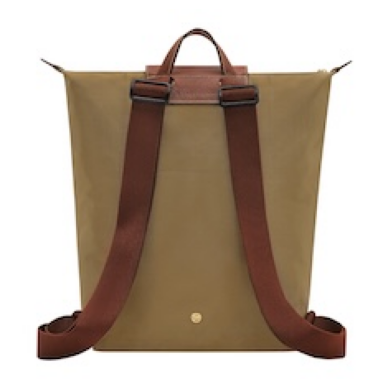

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
************************************


...........it is a BAG!


************************************




In [30]:
bag = "predict/bag.jpg"
shoe ="predict/shoe.jpg"

predict_image(bag)